# Chapter 20 · Signatures and signature-based models: interactive demos

Companion to Chapter 20 of the [IEOR 222 lecture notes](https://gennaroalberto.github.io/ieor222-financial-engineering/notes.pdf).
Each section draws a figure with default settings, then an **Explore** cell lets you move the parameters.
The sliders need a running kernel: open the notebook in
[Google Colab](https://colab.research.google.com/github/GennaroAlberto/ieor222-financial-engineering/blob/main/code/notebooks/20-signatures.ipynb)
or in Jupyter after `pip install -e "code[dev]"`.

Signatures are computed by our own NumPy code (`ieor222.signatures`), not by `iisignature` or `esig`.
All data are simulated or computed from models, so the notebook runs offline. To calibrate to market data, replace
the Heston quotes of Section 5 by mid-quotes of listed options: for each maturity, arrays of strikes, call prices
and Black–Scholes vegas, in the dictionary `quotes` (we do not ship market data).

In [1]:
# In Google Colab, this installs the course package from GitHub; elsewhere it does nothing.
import sys
if "google.colab" in sys.modules:
    %pip install -q "git+https://github.com/GennaroAlberto/ieor222-financial-engineering#subdirectory=code"

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider, FloatSlider, Dropdown

from ieor222 import signatures as sg
from ieor222.volatility import bs_call, heston_call, implied_vol, black_vega_normalized
from ieor222.style import COBALT, GOLD, GREY, INK, PALETTE, use_style

GREEN = PALETTE[2]
use_style()

## 1. The signature of a planar path: Chen, shuffles, Lévy area

A planar path $x_t = (r_t\cos\theta_t,\ r_t\sin\theta_t)$ is sampled at 200 points and joined by segments. Its
signature is computed one segment at a time, $S \leftarrow S\otimes\exp(v)$ (Theorem 20.5, Corollary 20.6). The
printout checks Chen's identity (signature of the whole path against the product of the signatures of the two halves)
and the shuffle identity $\mathrm{Sig}^I\mathrm{Sig}^J = \langle e_I \sqcup\!\sqcup\, e_J, \mathrm{Sig}\rangle$ (Proposition 20.7)
for all pairs of words of total length at most the depth. The Lévy area $\frac12(\mathrm{Sig}^{12}-\mathrm{Sig}^{21})$ is the
signed area between the path and its chord: compare it with the shoelace formula.

The second panel adds a detour that goes out along a branch and comes back the same way. It is tree-like, and the
signature does not change (Theorem 20.8).

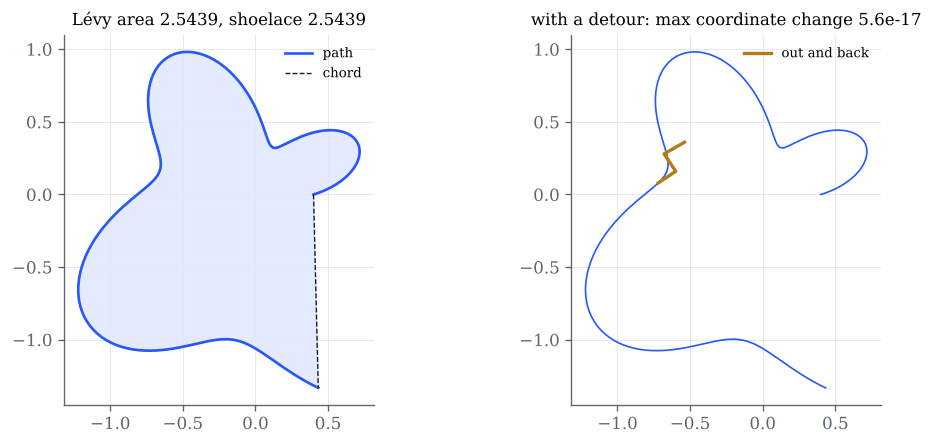

depth 4: 31 coordinates; Chen error 1.3e-15; shuffle error 7.1e-15


In [2]:
def planar(turns=0.8, wobble=0.3, depth=4, detour=0.4):
    s = np.linspace(0, 1, 200)
    theta = 2 * np.pi * turns * s
    r = 0.4 + s + wobble * np.sin(6 * np.pi * s)
    x = np.stack([r * np.cos(theta), r * np.sin(theta)], axis=1)
    S = sg.signature(x, depth)
    half = sg.tensor_mul(sg.signature(x[:101], depth), sg.signature(x[100:], depth))
    chen = max(np.max(np.abs(a - b)) for a, b in zip(S, half))
    shuf = 0.0
    for u in sg.words(2, depth, 1):
        for v in sg.words(2, depth - len(u), 1):
            shuf = max(shuf, abs(sg.coefficient(S, u, 2) * sg.coefficient(S, v, 2) - sg.pair(sg.shuffle(u, v), S, 2)))
    area = 0.5 * (S[2][1] - S[2][2])
    closed = np.vstack([x, x[:1]])
    shoelace = 0.5 * np.sum(closed[:-1, 0] * closed[1:, 1] - closed[1:, 0] * closed[:-1, 1])
    j = 120                                    # detour: out along a branch and back
    branch = x[j] + detour * np.array([[0, 0], [0.3, 0.2], [0.1, 0.5], [0.45, 0.7]])
    y = np.concatenate([x[:j + 1], branch[1:], branch[::-1][1:], x[j + 1:]])
    Sy = sg.signature(y, depth)
    gap = max(np.max(np.abs(a - b)) for a, b in zip(S, Sy))
    fig, axs = plt.subplots(1, 2, figsize=(10, 4))
    axs[0].fill(closed[:, 0], closed[:, 1], color=COBALT, alpha=0.12)
    axs[0].plot(x[:, 0], x[:, 1], color=COBALT, label="path")
    axs[0].plot([x[0, 0], x[-1, 0]], [x[0, 1], x[-1, 1]], color=INK, ls="--", lw=0.8, label="chord")
    axs[0].set(title=f"Lévy area {area:.4f}, shoelace {shoelace:.4f}", aspect="equal")
    axs[0].legend(fontsize=8)
    axs[1].plot(y[:, 0], y[:, 1], color=COBALT, lw=1)
    axs[1].plot(branch[:, 0], branch[:, 1], color=GOLD, lw=2, label="out and back")
    axs[1].set(title=f"with a detour: max coordinate change {gap:.1e}", aspect="equal")
    axs[1].legend(fontsize=8)
    plt.show()
    print(f"depth {depth}: {sum(2**k for k in range(depth + 1))} coordinates; Chen error {chen:.1e}; "
          f"shuffle error {shuf:.1e}")

planar()

In [3]:
# Explore: the identities hold to rounding error for every path and depth.
interact(planar,
         turns=FloatSlider(value=0.8, min=0.1, max=2.0, step=0.05, continuous_update=False, description="turns"),
         wobble=FloatSlider(value=0.3, min=0.0, max=0.6, step=0.05, continuous_update=False, description="wobble"),
         depth=IntSlider(value=4, min=2, max=7, continuous_update=False, description="depth"),
         detour=FloatSlider(value=0.4, min=0.0, max=1.0, step=0.05, continuous_update=False, description="detour"));

## 2. Brownian paths: the piecewise linear signature is Stratonovich

Two Brownian motions with correlation $\rho$ are interpolated linearly on $n$ intervals of $[0,1]$. Along every
partition, $\mathrm{Sig}^{12}$ equals the left-point (Itô) sum plus half the covariation sum
(Proposition 20.11), so as $n$ grows it converges to $\int_0^1 W^1\,dW^2 + \rho/2$, the Stratonovich integral, while
the Itô sum converges to $\int_0^1 W^1\,dW^2$. The right panel shows the gap over many paths, against its exact
root-mean-square value $\frac12\sqrt{(1+\rho^2)/n}$.

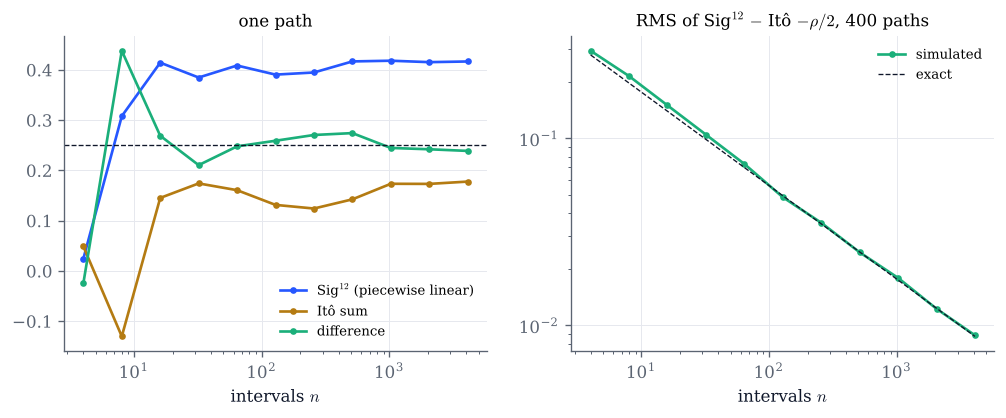

In [4]:
def level2(rho=0.5, n_paths=400, seed=1):
    K = 12
    t, W = sg.correlated_brownian(1.0, 2**K, [[1, rho], [rho, 1]], n_paths, seed=seed)
    ns = 2 ** np.arange(2, K + 1)
    s12, ito = [], []
    for n in ns:
        Wn = W[:, :: 2**K // n]
        s12.append(sg.level2(Wn)[:, 0, 1])
        ito.append(np.sum(Wn[:, :-1, 0] * np.diff(Wn[:, :, 1], axis=1), axis=1))
    s12, ito = np.array(s12), np.array(ito)
    fig, axs = plt.subplots(1, 2, figsize=(10, 3.4))
    axs[0].plot(ns, s12[:, 0], color=COBALT, marker="o", ms=3, label="Sig$^{12}$ (piecewise linear)")
    axs[0].plot(ns, ito[:, 0], color=GOLD, marker="o", ms=3, label="Itô sum")
    axs[0].plot(ns, s12[:, 0] - ito[:, 0], color=GREEN, marker="o", ms=3, label="difference")
    axs[0].axhline(rho / 2, color=INK, ls="--", lw=0.8)
    axs[0].set(xscale="log", xlabel="intervals $n$", title="one path")
    axs[0].legend(fontsize=8)
    gap = np.sqrt(np.mean((s12 - ito - rho / 2) ** 2, axis=1))
    axs[1].plot(ns, gap, color=GREEN, marker="o", ms=3, label="simulated")
    axs[1].plot(ns, 0.5 * np.sqrt((1 + rho**2) / ns), color=INK, ls="--", lw=0.8, label="exact")
    axs[1].set(xscale="log", yscale="log", xlabel="intervals $n$", title=f"RMS of Sig$^{{12}}$ $-$ Itô $-\\rho/2$, {n_paths} paths")
    axs[1].legend(fontsize=8)
    plt.show()

level2()

In [5]:
interact(level2,
         rho=FloatSlider(value=0.5, min=-1.0, max=1.0, step=0.1, continuous_update=False, description="ρ"),
         n_paths=IntSlider(value=400, min=50, max=2000, step=50, continuous_update=False, description="paths"),
         seed=IntSlider(value=1, min=0, max=50, continuous_update=False, description="seed"));

## 3. The expected signature of Brownian motion with time

For $\widehat X_t=(t,W^1_t,W^2_t)$ with correlation $\rho$, Proposition 20.13(iv) gives
$\mathbb E[\mathrm{Sig}(\widehat X)_{0,t}] = \exp\big(t(e_0+\tfrac12\sum_{ij}\rho_{ij}e_{ij})\big)$. The table compares a few
coordinates with Monte Carlo averages of piecewise linear signatures, and with the exact expectation of the
piecewise linear signature on the grid, $(\mathbb E\exp(h e_0+\Delta W))^{\otimes m}$, which differs from the Brownian one
by $O(h)$.

In [6]:
def expected(rho=0.5, t=1.0, steps=50, n_paths=10_000, seed=2):
    corr = [[1, rho], [rho, 1]]
    E = sg.brownian_expected_signature(t, corr, 3)
    Eh = sg.expected_signature_random_walk(t, steps, corr, 3)
    tt, W = sg.correlated_brownian(t, steps, corr, n_paths, seed=seed, antithetic=True)
    S = sg.signature(sg.time_augment(tt, W), 3)
    print(f"{'word':>10} {'Brownian':>10} {'grid exact':>11} {'Monte Carlo':>12} {'s.e.':>8}")
    for w in [(1, 1), (1, 2), (0, 1, 1), (1, 1, 0), (1, 0, 1), (0, 1, 2), (2, 1, 0), (0, 0)]:
        mc = sg.coefficient(S, w, 3)
        print(f"{str(w):>10} {sg.coefficient(E, w, 3):10.5f} {sg.coefficient(Eh, w, 3):11.5f} "
              f"{mc.mean():12.5f} {mc.std() / np.sqrt(mc.size):8.5f}")

expected()

      word   Brownian  grid exact  Monte Carlo     s.e.
    (1, 1)    0.50000     0.50000      0.50725  0.00706
    (1, 2)    0.25000     0.25000      0.25043  0.00689
 (0, 1, 1)    0.25000     0.24833      0.25310  0.00299
 (1, 1, 0)    0.25000     0.24833      0.24619  0.00284
 (1, 0, 1)    0.00000     0.00333      0.00796  0.00283
 (0, 1, 2)    0.12500     0.12417      0.12300  0.00288
 (2, 1, 0)    0.12500     0.12417      0.12348  0.00284
    (0, 0)    0.50000     0.50000      0.50000  0.00000


In [7]:
interact(expected,
         rho=FloatSlider(value=0.5, min=-1.0, max=1.0, step=0.1, continuous_update=False, description="ρ"),
         t=FloatSlider(value=1.0, min=0.1, max=3.0, step=0.1, continuous_update=False, description="t"),
         steps=IntSlider(value=50, min=2, max=200, continuous_update=False, description="steps"),
         n_paths=IntSlider(value=10_000, min=1_000, max=40_000, step=1_000, continuous_update=False, description="paths"),
         seed=IntSlider(value=2, min=0, max=50, continuous_update=False, description="seed"));

## 4. Learning a path functional from the signature

Theorem 20.10 says that continuous functionals of (time-augmented) paths are uniform limits of linear functionals of
the signature on compact sets. In practice one regresses: here the Asian call $(\int_0^1S_t\,dt-K)^+$ with
$S_t=e^{\sigma W_t-\sigma^2t/2}$, and the maximum of $W$, are fitted by least squares on $\mathrm{Sig}^N(\widehat W)_{0,1}$
on half the paths, and the $R^2$ is measured on the other half (Figure 20.2 of the notes).

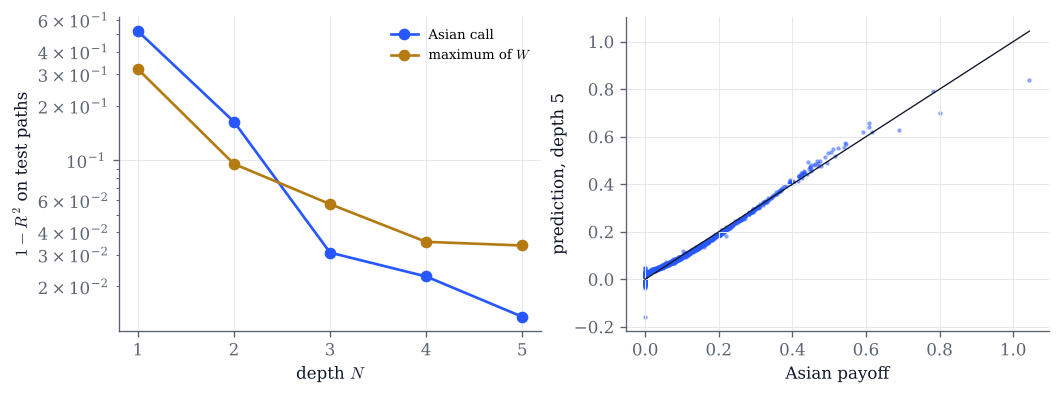

R^2 by depth: {'asian': [0.481, 0.837, 0.969, 0.977, 0.986], 'max': [0.68, 0.905, 0.943, 0.965, 0.966]}


In [8]:
def regression(sigma=0.3, strike=1.0, n_paths=4000, max_depth=5, seed=3):
    depths = tuple(range(1, max_depth + 1))
    res = sg.regression_experiment(depths=depths, n_paths=n_paths, n_steps=60, sigma=sigma, strike=strike, seed=seed)
    fig, axs = plt.subplots(1, 2, figsize=(10, 3.4))
    for (name, lab), c in zip((("asian", "Asian call"), ("max", "maximum of $W$")), (COBALT, GOLD)):
        axs[0].plot(depths, 1 - res[name][0], color=c, marker="o", label=lab)
    axs[0].set(yscale="log", xlabel="depth $N$", ylabel="$1-R^2$ on test paths")
    axs[0].legend(fontsize=8)
    _, y, pred = res["asian"]
    axs[1].scatter(y, pred, s=3, color=COBALT, alpha=0.4)
    axs[1].plot([y.min(), y.max()], [y.min(), y.max()], color=INK, lw=0.8)
    axs[1].set(xlabel="Asian payoff", ylabel=f"prediction, depth {max_depth}")
    plt.show()
    print("R^2 by depth:", {k: np.round(v[0], 3).tolist() for k, v in res.items()})

regression()

In [9]:
# Explore: which payoffs are hard to learn? Try a deep out-of-the-money strike.
interact(regression,
         sigma=FloatSlider(value=0.3, min=0.05, max=0.8, step=0.05, continuous_update=False, description="σ"),
         strike=FloatSlider(value=1.0, min=0.8, max=1.4, step=0.05, continuous_update=False, description="K"),
         n_paths=IntSlider(value=4000, min=1000, max=10_000, step=500, continuous_update=False, description="paths"),
         max_depth=IntSlider(value=5, min=1, max=6, continuous_update=False, description="max depth"),
         seed=IntSlider(value=3, min=0, max=50, continuous_update=False, description="seed"));

## 5. Calibrating a linear signature model

The model of Proposition 20.15: $S_t = 1+\sum_{|I|\le n-1}\ell_I\int_0^t\langle e_I,\mathrm{Sig}(\widehat X)_{0,u}\rangle\,dW^1_u$, with primary
process $\widehat X=(t,W^1,W^2)$, correlation $\rho_{12}$ between the two Brownian motions. The signature features are
simulated once; then $\ell$ is fitted by vega-weighted least squares to call prices (Section 20.4 and Example 20.17 of the
notes). The target is the Heston model of Chapter 15 ($v_0=\theta=0.04$, $\kappa=2$, $\xi$, $\rho$ adjustable) or Black–Scholes at
$20\%$. The left panel shows the targets and the model repriced on independent paths; the right panel the errors in basis
points, on the calibration paths (open markers) and on independent paths (lines), with the Monte Carlo standard error.

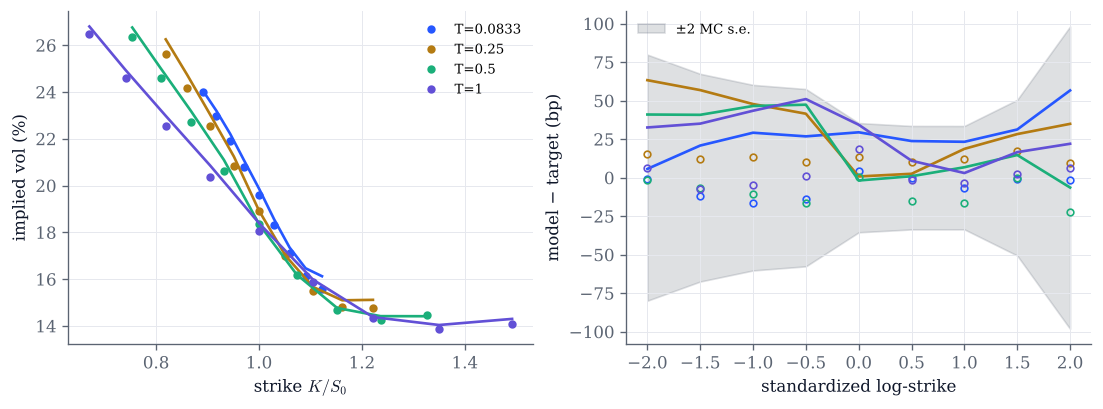

13 parameters; RMS error 10.7 bp on the calibration paths, 32.8 bp on independent paths; Q(S_1 <= 0) = 6.5e-04; simulation 0.8s, fit 0.4s


In [10]:
def calibrate(n=3, target="Heston", xi=0.5, rho=-0.7, rho12=-0.5, n_paths=20_000, seed=7):
    heston = dict(v0=0.04, kappa=2.0, theta=0.04, xi=xi, rho=rho) if target == "Heston" else dict(v0=0.04, kappa=2.0, theta=0.04, xi=1e-4, rho=0.0)
    r = sg.calibration_experiment(n=n, heston=heston, rho12=rho12, n_paths=n_paths, n_check=n_paths, seed=seed)
    Ts = sorted(r["iv_market"])
    fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
    for T, c in zip(Ts, PALETTE):
        K = r["quotes"][T][0]
        axs[0].plot(K, 100 * r["iv_market"][T], "o", color=c, ms=4, label=f"T={T:.3g}")
        axs[0].plot(K, 100 * r["iv_out"][T], color=c)
        axs[1].plot(r["x"], 1e4 * (r["iv_in"][T] - r["iv_market"][T]), "o", mfc="none", color=c, ms=4)
        axs[1].plot(r["x"], 1e4 * (r["iv_out"][T] - r["iv_market"][T]), color=c)
    se = np.max([np.hypot(r["iv_se"][T], r["iv_se_fit"][T]) for T in Ts], axis=0)
    axs[1].fill_between(r["x"], -2e4 * se, 2e4 * se, color=GREY, alpha=0.2, label="±2 MC s.e.")
    axs[0].set(xlabel="strike $K/S_0$", ylabel="implied vol (%)")
    axs[0].legend(fontsize=8)
    axs[1].set(xlabel="standardized log-strike", ylabel="model − target (bp)")
    axs[1].legend(fontsize=8)
    plt.show()
    e_in = np.concatenate([r["iv_in"][T] - r["iv_market"][T] for T in Ts])
    e_out = np.concatenate([r["iv_out"][T] - r["iv_market"][T] for T in Ts])
    print(f"{len(r['words'])} parameters; RMS error {1e4*np.sqrt(np.mean(e_in**2)):.1f} bp on the calibration paths, "
          f"{1e4*np.sqrt(np.mean(e_out**2)):.1f} bp on independent paths; Q(S_1 <= 0) = {r['prob_negative'][Ts[-1]]:.1e}; "
          f"simulation {r['times'][0]:.1f}s, fit {r['times'][1]:.1f}s")

calibrate()

In [11]:
# Explore: n = 2 has 4 parameters, n = 3 has 13, n = 4 has 40 (slow: try fewer paths first).
interact(calibrate,
         n=IntSlider(value=3, min=1, max=4, continuous_update=False, description="n"),
         target=Dropdown(options=["Heston", "Black–Scholes"], value="Heston", description="target"),
         xi=FloatSlider(value=0.5, min=0.1, max=1.0, step=0.05, continuous_update=False, description="ξ"),
         rho=FloatSlider(value=-0.7, min=-0.95, max=0.5, step=0.05, continuous_update=False, description="ρ"),
         rho12=FloatSlider(value=-0.5, min=-0.95, max=0.95, step=0.05, continuous_update=False, description="ρ12"),
         n_paths=IntSlider(value=20_000, min=4_000, max=100_000, step=4_000, continuous_update=False, description="paths"),
         seed=IntSlider(value=7, min=0, max=50, continuous_update=False, description="seed"));

### How much of the error is Monte Carlo?

The seed study quoted in Example 20.17: the calibration of the notes ($n=3$: $50{,}000$ paths to fit, $60{,}000$ to check;
$n=2$: $30{,}000$ and $30{,}000$) repeated for five seeds. If the out-of-sample errors were model error, they would not
change sign with the seed. This cell takes about half a minute.

In [12]:
for seed in (7, 9, 11, 13, 15):
    out = []
    for n, N, M in ((3, 50_000, 60_000), (2, 30_000, 30_000)):
        r = sg.calibration_experiment(n=n, n_paths=N, n_check=M, seed=seed)
        Ts = sorted(r["iv_market"])
        e_in = np.concatenate([r["iv_in"][T] - r["iv_market"][T] for T in Ts])
        e_out = np.concatenate([r["iv_out"][T] - r["iv_market"][T] for T in Ts])
        out.append((1e4 * np.sqrt(np.mean(e_in**2)), 1e4 * np.sqrt(np.mean(e_out**2)),
                    1e4 * np.mean(r["iv_out"][Ts[0]] - r["iv_market"][Ts[0]])))
    (a, b, c), (d, e, _) = out
    print(f"seed {seed:2d}: n=3 RMS {a:4.1f} bp in sample, {b:4.1f} out of sample, one-month mean {c:+5.1f} bp | "
          f"n=2 RMS {d:4.1f} in, {e:4.1f} out")

seed  7: n=3 RMS  6.1 bp in sample, 19.7 out of sample, one-month mean +27.8 bp | n=2 RMS 65.8 in, 64.3 out


seed  9: n=3 RMS  4.3 bp in sample, 11.6 out of sample, one-month mean  -1.5 bp | n=2 RMS 69.0 in, 71.4 out


seed 11: n=3 RMS  4.9 bp in sample, 15.5 out of sample, one-month mean  -1.7 bp | n=2 RMS 71.2 in, 69.9 out


seed 13: n=3 RMS  5.3 bp in sample, 14.8 out of sample, one-month mean +13.4 bp | n=2 RMS 64.5 in, 74.1 out


seed 15: n=3 RMS  2.7 bp in sample, 15.2 out of sample, one-month mean  +3.3 bp | n=2 RMS 69.7 in, 65.1 out


## 6. VIX in a signature volatility model: a quadratic form

With volatility $\sigma_t=\langle\ell,\mathrm{Sig}(\widehat X)_{0,t}\rangle$ for $\widehat X=(t,W)$ and the words $\emptyset,0,1,11$,
Proposition 20.16(iii) gives $\mathbb E[\int_T^{T+\Delta}\sigma_u^2\,du\mid\mathcal F_T]=\ell^\top Q(T)\ell$, with $Q(T)$ a linear function
of the signature at $T$. Along one simulated path, the model VIX $=100\sqrt{\ell^\top Q(T)\ell/\Delta}$ with $\Delta=30$ days
is computed at every date from the stored signature alone; at one date it is checked against a nested Monte Carlo
simulation of the next 30 days.

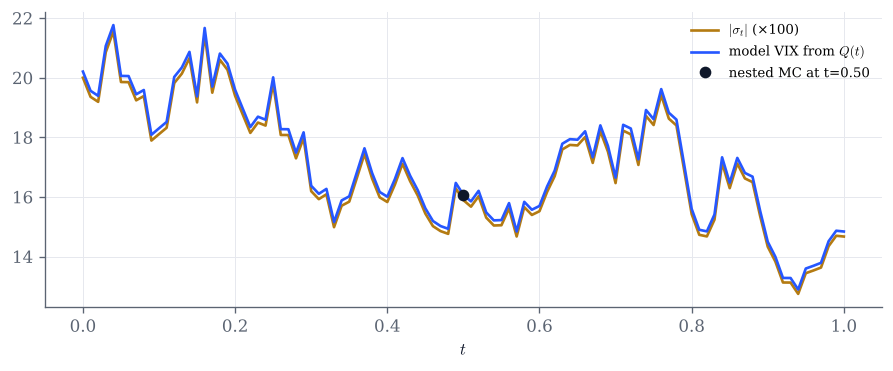

VIX at t=0.50: quadratic form 16.072, nested Monte Carlo 16.077 (4000 inner paths)


In [13]:
def vix(a=0.2, b=0.0, c=0.1, d=0.05, seed=4, check_at=0.5):
    words = [(), (0,), (1,), (1, 1)]
    ell = np.array([a, b, c, d])
    T, steps, Delta = 1.0, 100, 30 / 365
    t, W = sg.correlated_brownian(T, steps, [[1.0]], 1, seed=seed)
    X = sg.time_augment(t, W)[0]
    stream = sg.signature(X, 5, at=range(steps + 1))
    sigma = np.array([sum(l * sg.coefficient(S, w, 2) for l, w in zip(ell, words)) for S in stream])
    vixs = np.array([100 * np.sqrt(ell @ sg.vix2_quadratic_form(words, S, [[1.0]], Delta) @ ell / Delta) for S in stream])
    j = int(round(check_at * steps))
    m, N = 30, 4000
    t2, W2 = sg.correlated_brownian(Delta, m, [[1.0]], N, seed=seed + 100, antithetic=True)
    inner = sg.signature(sg.time_augment(t2, W2), 2, at=range(m + 1))
    base = [np.broadcast_to(x, (N,) + np.shape(x)) for x in sg.signature(X[: j + 1], 2)]
    vals = np.array([sum(l * sg.coefficient(sg.tensor_mul(base, s), w, 2) for l, w in zip(ell, words)) ** 2 for s in inner])
    integral = np.sum(0.5 * (vals[1:] + vals[:-1]), axis=0) * Delta / m
    nested = 100 * np.sqrt(integral.mean() / Delta)
    fig, ax = plt.subplots(figsize=(9, 3.2))
    ax.plot(t, 100 * np.abs(sigma), color=GOLD, label="$|\\sigma_t|$ (×100)")
    ax.plot(t, vixs, color=COBALT, label="model VIX from $Q(t)$")
    ax.plot([t[j]], [nested], "o", color=INK, label=f"nested MC at t={t[j]:.2f}")
    ax.set(xlabel="$t$")
    ax.legend(fontsize=8)
    plt.show()
    print(f"VIX at t={t[j]:.2f}: quadratic form {vixs[j]:.3f}, nested Monte Carlo {nested:.3f} ({N} inner paths)")

vix()

In [14]:
interact(vix,
         a=FloatSlider(value=0.2, min=0.0, max=0.5, step=0.01, continuous_update=False, description="ℓ_∅"),
         b=FloatSlider(value=0.0, min=-0.2, max=0.2, step=0.01, continuous_update=False, description="ℓ_0"),
         c=FloatSlider(value=0.1, min=-0.3, max=0.3, step=0.01, continuous_update=False, description="ℓ_1"),
         d=FloatSlider(value=0.05, min=-0.2, max=0.2, step=0.01, continuous_update=False, description="ℓ_11"),
         seed=IntSlider(value=4, min=0, max=50, continuous_update=False, description="seed"),
         check_at=FloatSlider(value=0.5, min=0.0, max=1.0, step=0.05, continuous_update=False, description="check at"));

## Things to try

* In Section 1, set the depth to 2 and find two different paths with the same level-2 signature. What changes at depth 3?
* In Section 2, set $\rho=1$: the two coordinates are the same Brownian motion, and $\mathrm{Sig}^{12}=\frac12 W_1^2$ for every $n$.
  Which result of Chapter 7 is this?
* In Section 3, take 2 steps on a long horizon: which coordinates of the grid expectation are far from the Brownian ones, and
  why are $(1,1)$ and $(1,2)$ always exact?
* In Section 4, raise the strike of the Asian call. Why does the regression get worse as the payoff becomes rarer?
* In Section 5, compare $n=2$ and $n=3$ with 4,000 and with 60,000 paths. When does the in-sample error mislead you? Try the
  Black–Scholes target with $n=1$: what does a Bachelier model do to the smile?
* In Section 6, set $\ell_1=\ell_{11}=0$: why do the VIX and the volatility then become deterministic functions of time?